In [1]:

import pandas as pd
import numpy as np

from pathlib import Path

# Load original sales and official split files
raw_dir = Path("../data/raw")

sales = pd.read_csv(raw_dir / "sales.csv")
split_train = pd.read_csv(raw_dir / "stfore_train.csv")
split_test = pd.read_csv(raw_dir / "stfore_test.csv")

key_cols = [
    "external_code",
    "retail",
    "season",
    "release_date"
]

weekly_cols = [str(i) for i in range(12)]

# Recover original, unnormalized sales records
train_data = sales.merge(
    split_train[key_cols],
    on=key_cols,
    how="inner",
    validate="one_to_one"
)

test_data = sales.merge(
    split_test[key_cols],
    on=key_cols,
    how="inner",
    validate="one_to_one"
)

# Sort is not necessary for modelling, but reset indexes
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

# Features available at the time of forecasting
def prepare_features(df):
    X = df[
        ["category", "color", "fabric", "season", "retail"]
    ].copy()

    release_dates = pd.to_datetime(
        df["release_date"],
        errors="coerce"
    )

    X["release_month"] = release_dates.dt.month
    X["release_year"] = release_dates.dt.year

    # Observed sales during the first two weeks
    X["week_0_sales"] = df["0"]
    X["week_1_sales"] = df["1"]
    X["first_2_weeks_total"] = df["0"] + df["1"]

    return X

# Predict weeks 2–11
target_cols = [str(i) for i in range(2, 12)]

X_train = prepare_features(train_data)
X_test = prepare_features(test_data)

y_train = train_data[target_cols].copy()
y_test = test_data[target_cols].copy()

print("FORECASTING DATASET")
print("-------------------")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nMissing training features:")
print(X_train.isnull().sum().sum())

print("\nMissing testing features:")
print(X_test.isnull().sum().sum())

print("\nTraining target range:")
print(y_train.min().min(), "to", y_train.max().max())

print("\nTesting target range:")
print(y_test.min().min(), "to", y_test.max().max())

print("\nTraining and testing records:")
print(len(train_data), len(test_data))


FORECASTING DATASET
-------------------
Training features: (96166, 10)
Testing features: (10684, 10)
Training targets: (96166, 10)
Testing targets: (10684, 10)

Missing training features:
0

Missing testing features:
0

Training target range:
-3.0 to 53.0

Testing target range:
-3.0 to 34.0

Training and testing records:
96166 10684


In [2]:

# Count negative sales values in each future week

print("NEGATIVE SALES COUNTS BY WEEK")
print("--------------------------------")

negative_counts = (y_train < 0).sum()

display(negative_counts.rename("Negative Records"))

print("\nTotal negative values in training:",
      (y_train < 0).sum().sum())

print("Total negative values in testing:",
      (y_test < 0).sum().sum())

# Inspect records containing negative future sales
negative_rows = train_data[
    (train_data[target_cols] < 0).any(axis=1)
].copy()

print("\nRecords containing negative sales:",
      len(negative_rows))

# Show relevant product and sales information
display(
    negative_rows[
        [
            "external_code",
            "retail",
            "category",
            "season",
            "0",
            "1",
            *target_cols
        ]
    ].head(15)
)

# Check the distinct negative values
print("\nDistinct negative values:")
print(
    pd.unique(
        y_train.to_numpy().flatten()[
            y_train.to_numpy().flatten() < 0
        ]
    )
)


NEGATIVE SALES COUNTS BY WEEK
--------------------------------


2       0
3       0
4     752
5     797
6       0
7       0
8       0
9     737
10    678
11      0
Name: Negative Records, dtype: int64


Total negative values in training: 2964
Total negative values in testing: 422

Records containing negative sales: 2939


,external_code,retail,category,season,0,1,2,3,4,5,6,7,8,9,10,11
103,10,8,miniskirt,SS17,2.0,1.0,2.0,0.0,2.0,1.0,1.0,0.0,0.0,-1.0,0.0,1.0
122,10,19,miniskirt,SS17,2.0,2.0,5.0,0.0,-1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0
156,6,27,long sleeve,SS17,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,-1.0,0.0
163,9,10,culottes,SS17,3.0,2.0,1.0,2.0,2.0,3.0,1.0,0.0,1.0,-1.0,0.0,0.0
222,61,36,long dress,SS17,1.0,0.0,1.0,1.0,0.0,0.0,0.0,4.0,1.0,-1.0,1.0,2.0
338,84,22,culottes,SS17,1.0,0.0,0.0,1.0,1.0,-1.0,0.0,1.0,1.0,0.0,0.0,0.0
383,87,48,culottes,SS17,1.0,0.0,3.0,3.0,5.0,3.0,5.0,3.0,3.0,-1.0,1.0,0.0
399,102,19,culottes,SS17,0.0,1.0,0.0,0.0,1.0,1.0,1.0,2.0,5.0,1.0,-2.0,0.0
431,84,0,culottes,SS17,2.0,2.0,3.0,0.0,-1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
472,76,8,long sleeve,SS17,1.0,2.0,0.0,0.0,1.0,2.0,0.0,0.0,1.0,-1.0,0.0,0.0



Distinct negative values:
[-1. -2. -3.]


In [3]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Baseline: average demand from the first two weeks
baseline_value = (
    X_test["week_0_sales"] + X_test["week_1_sales"]
) / 2

# Repeat the average across all 10 forecast weeks
baseline_predictions = np.repeat(
    baseline_value.to_numpy().reshape(-1, 1),
    10,
    axis=1
)

# Prevent negative demand predictions
baseline_predictions = np.maximum(baseline_predictions, 0)

# Evaluation
actual = y_test.to_numpy()
predicted = baseline_predictions

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

# Weighted Absolute Percentage Error
wape = (
    np.abs(actual - predicted).sum()
    / np.abs(actual).sum()
) * 100

print("BASELINE MODEL RESULTS")
print("----------------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"WAPE: {wape:.2f}%")


BASELINE MODEL RESULTS
----------------------
MAE:  1.2287
RMSE: 1.7385
WAPE: 109.00%


In [4]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

import numpy as np
import pandas as pd

# Separate categorical and numerical features
categorical_features = [
    "category", "color", "fabric", "season", "retail"
]

numerical_features = [
    "release_month",
    "release_year",
    "week_0_sales",
    "week_1_sales",
    "first_2_weeks_total"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("num", "passthrough", numerical_features)
    ]
)

# Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_features=0.7,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
print("Training Random Forest...")
rf_model.fit(X_train, y_train)

# Predict all 10 future weeks
rf_predictions = rf_model.predict(X_test)

# Prevent negative demand forecasts
rf_predictions = np.maximum(rf_predictions, 0)

# Evaluate
actual = y_test.to_numpy()

rf_mae = mean_absolute_error(actual, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(actual, rf_predictions))

rf_wape = (
    np.abs(actual - rf_predictions).sum()
    / np.abs(actual).sum()
) * 100

print("\nRANDOM FOREST RESULTS")
print("---------------------")
print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"WAPE: {rf_wape:.2f}%")


Training Random Forest...

RANDOM FOREST RESULTS
---------------------
MAE:  1.0103
RMSE: 1.5468
WAPE: 89.63%


In [5]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [1.2287, rf_mae],
    "RMSE": [1.7385, rf_rmse],
    "WAPE (%)": [109.00, rf_wape]
})

model_comparison

,Model,MAE,RMSE,WAPE (%)
0,Baseline,1.228700,1.738500,109.000000
1,Random Forest,1.010305,1.546844,89.625939


In [6]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

et_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=100,
        max_features=0.7,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Extra Trees...")
et_model.fit(X_train, y_train)

et_predictions = et_model.predict(X_test)
et_predictions = np.maximum(et_predictions, 0)

et_mae = mean_absolute_error(actual, et_predictions)
et_rmse = np.sqrt(mean_squared_error(actual, et_predictions))
et_wape = (
    np.abs(actual - et_predictions).sum()
    / np.abs(actual).sum()
) * 100

print("\nEXTRA TREES RESULTS")
print("-------------------")
print(f"MAE:  {et_mae:.4f}")
print(f"RMSE: {et_rmse:.4f}")
print(f"WAPE: {et_wape:.2f}%")

Training Extra Trees...

EXTRA TREES RESULTS
-------------------
MAE:  1.0240
RMSE: 1.5622
WAPE: 90.84%


In [7]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Random Forest", "Extra Trees"],
    "MAE": [1.2287, rf_mae, et_mae],
    "RMSE": [1.7385, rf_rmse, et_rmse],
    "WAPE (%)": [109.00, rf_wape, et_wape]
})

model_comparison

,Model,MAE,RMSE,WAPE (%)
0,Baseline,1.228700,1.738500,109.000000
1,Random Forest,1.010305,1.546844,89.625939
2,Extra Trees,1.023950,1.562209,90.836440


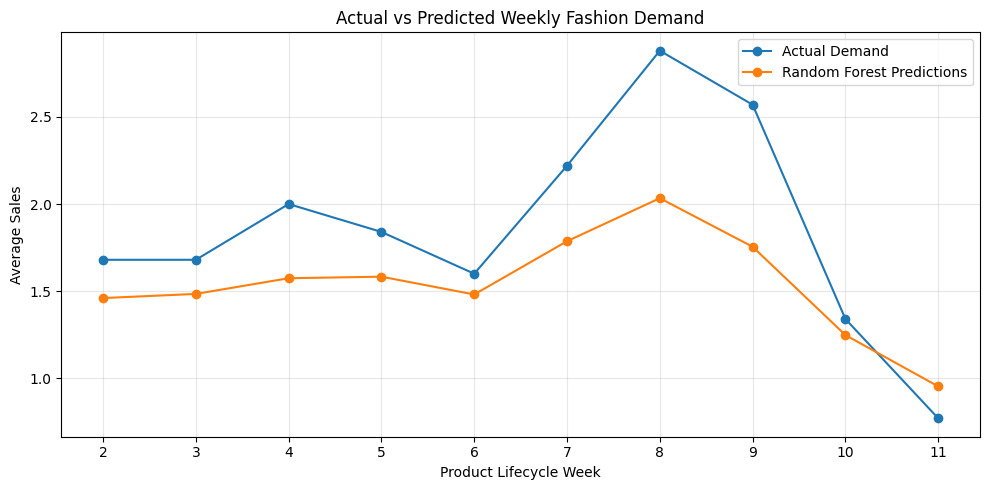

In [8]:
import matplotlib.pyplot as plt

sample_size = 100
sample_actual = actual[:sample_size]
sample_predicted = rf_predictions[:sample_size]

actual_weekly_mean = sample_actual.mean(axis=0)
predicted_weekly_mean = sample_predicted.mean(axis=0)

weeks = range(2, 12)

plt.figure(figsize=(10, 5))

plt.plot(
    weeks, actual_weekly_mean,
    marker="o", label="Actual Demand"
)

plt.plot(
    weeks, predicted_weekly_mean,
    marker="o", label="Random Forest Predictions"
)

plt.title("Actual vs Predicted Weekly Fashion Demand")
plt.xlabel("Product Lifecycle Week")
plt.ylabel("Average Sales")
plt.xticks(weeks)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
weekly_comparison = pd.DataFrame({
    "Week": [f"Week {i}" for i in range(2, 12)],
    "Actual_Average": actual.mean(axis=0),
    "Predicted_Average": rf_predictions.mean(axis=0)
})

weekly_comparison["Difference"] = (
    weekly_comparison["Predicted_Average"]
    - weekly_comparison["Actual_Average"]
)

weekly_comparison

,Week,Actual_Average,Predicted_Average,Difference
0,Week 2,1.355204,1.254399,-0.100805
1,Week 3,1.422127,1.322990,-0.099137
2,Week 4,1.303444,1.200758,-0.102686
3,Week 5,1.453950,1.181599,-0.272351
4,Week 6,1.447024,1.127232,-0.319791
5,Week 7,1.208536,1.137686,-0.070850
6,Week 8,0.988300,1.180212,0.191912
7,Week 9,0.834425,0.976534,0.142109
8,Week 10,0.678210,0.739130,0.060920
9,Week 11,0.500749,0.636128,0.135379


### Prediction Bias Analysis

The weekly comparison between actual and predicted demand revealed that the Random Forest model tends to underestimate demand during the earlier forecast period (Weeks 2–7) and overestimate demand during the later period (Weeks 8–11).

The largest underestimation was observed in Week 6, with a difference of approximately -0.32 sales units. The largest overestimation occurred in Week 8, with a difference of approximately 0.19 sales units.

These results indicate that although Random Forest achieved the best overall performance among the evaluated models, it does not fully capture weekly demand variations across the product lifecycle.